# Transformation Interpolations:  LSST DP2 <--> GAIA DR3

_Douglas L. Tucker_, _Christina Adair_

_2026.04.02_

## 1. Import Modules

In [1]:
import numpy as np
import pandas as pd

from lsst.daf.butler import Butler
import lsst.geom as geom

import pyvo

import os
import sys
import glob
import math
import datetime
import re

import pickle

from tqdm.notebook import tqdm

from collections import OrderedDict as odict

from astropy.io import fits
from astropy.table import Table
from astropy.coordinates import SkyCoord
import astropy.units as u

import fitsio

from scipy import interpolate
from scipy.optimize import leastsq

import healpy as hp

import plotly
from plotly.offline import download_plotlyjs, plot, iplot
import plotly.graph_objs as go

from IPython.display import Markdown, display

import matplotlib.pyplot as plt

%matplotlib inline

## 2.  Input Parameters

In [2]:
# LSST-->Gaia DR3 (toLSST=False) or Gaia DR3-->LSST (toLSST=True)...
#toLSST = True
toLSST = False

if toLSST:
    # List of LSST bands on which to run the transform fit...
    bandList = ['g_LSST', 'r_LSST', 'i_LSST', 'z_LSST', 'y_LSST']
    #bandList = ['g_LSST', 'r_LSST', 'i_LSST', 'y_LSST']
    # If Euclid-->LSST, then the mag and color to fit against are LSST...
    # Dictionary of corresponding bands from the other survey...
    matchBand_dict = {'g_LSST':'G_gaia', 'r_LSST':'G_gaia', 'i_LSST':'G_gaia', 'z_LSST':'G_gaia', 'y_LSST':'G_gaia'}
    #matchBand_dict = {'g_LSST':'G_gaia', 'r_LSST':'G_gaia', 'i_LSST':'G_gaia', 'y_LSST':'G_gaia'}
    # Color to fit against...
    color_name_1_dict = {'g_LSST':'BP_RP_gaia', 'r_LSST':'BP_RP_gaia', 'i_LSST':'BP_RP_gaia', 'z_LSST':'BP_RP_gaia', 'y_LSST':'BP_RP_gaia'}
    #color_name_1_dict = {'g_LSST':'BP_RP_gaia', 'r_LSST':'BP_RP_gaia', 'i_LSST':'BP_RP_gaia', 'y_LSST':'BP_RP_gaia'}
    # Name of color_name_1 as the label in the QA plots...
    colorLabel_1_dict = {'g_LSST':'(BP−RP)gaia', 'r_LSST':'(BP−RP)gaia', 'i_LSST':'(BP-RP)_{gaia}', 'z_LSST':'(BP−RP)gaia', 'y_LSST':'(BP−RP)gaia'}
    #colorLabel_1_dict = {'g_LSST':'$(BP-RP)_{gaia}$', 'r_LSST':'$(BP-RP)_{gaia}$', 'i_LSST':'(BP-RP)_{gaia}', 'y_LSST':'$(BP-RP)_{gaia}$'}

else:
    # List of EUCLID bands on which to run the transform fit...
    bandList = ['G_gaia', 'BP_gaia', 'RP_gaia' ]
    # If DES-->Stetson, then the mag and color to fit against are DES...
    # Dictionary of corresponding bands from the other survey...
    matchBand_dict = {'G_gaia':'r_LSST', 'BP_gaia':'g_LSST', 'RP_gaia':'r_LSST'}
    # Color to fit against...
    color_name_1_dict = {'G_gaia':'gi_LSST', 'BP_gaia':'gi_LSST', 'RP_gaia':'gi_LSST'}
    # Name of color_name_1 as the label in the QA plots...
    colorLabel_1_dict = {'G_gaia':'(g−i)LSST', 'BP_gaia':'(g−i)LSST', 'RP_gaia':'(g−i)LSST'}


# Size of the binsize in color
color_binsize = 0.10

# LSST data
#collection='LSSTCam/runs/DRP/20250515-20251214/v30_0_0_rc2/DM-53697'
#collection = 'LSSTCam/runs/DRP/DP2/v30_0_0/DM-53881/stage3'
collection = 'LSSTCam/runs/DRP/DP2'

repo = 'dp2_prep'
skymap = 'lsst_cells_v2'
instrument = 'LSSTCam'

# Gaia DR3 data
gaia_tap_url = 'https://gaia.aip.de/tap'

#use match file?
useMatchFile = True

## Name of the match file in matchDir
matchFile = './match_LSST_DP2_GAIA_DR3.csv'
#matchFile = './match_LSST_GAIA_DR3_47Tuc.csv'

# Name of Aitoff projection PNG plot of the matched file
aitoffPlotFileName = 'match_LSST_DP2_DES_DR2.png'

# Base name of fit results output file...
if toLSST:
    resultsFileBaseName = 'transInterp.GaiaDR3_to_LSST_DR2'
    #resultsFileBaseName = 'transInterp.GaiaDR3_to_LSST_47Tuc'
else:
    resultsFileBaseName = 'transInterp.LSST_DR2_to_GaiaDR3'
    #resultsFileBaseName = 'transInterp.LSST_to_GaiaDR3_47Tuc'

# Base name of QA plot output files...
if toLSST:
    qaFileBaseName = 'qaPlot.GaiaDR3_to_LSST_DR2.interp.fit'
    #qaFileBaseName = 'qaPlot.GaiaDR3_to_LSST_47Tuc.interp.fit'
else:
    qaFileBaseName = 'qaPlot.GaiaDR3_to_LSST_DR2.interp.fit'
    #qaFileBaseName = 'qaPlot.GaiaDR3_to_LSST_47Tuc.interp.fit'

# Write a Markdown-formatted summary table of the fits?
write_md_file = True
if write_md_file:
    # Auto-name the .md file based on resultsFileBaseName
    #md_filename = f"{qaFileBaseName}.qa_summary.md"
    md_filename = f"{resultsFileBaseName}.qa_summary.md"

# Verbosity level (0, 1, 2, 3, ...)
verbose = 2



## 3. Define Useful Functions

In [3]:
# Useful class to stop "Run All" at a cell 
#  containing the command "raise StopExecution"
class StopExecution(Exception):
    def _render_traceback_(self):
        pass

In [4]:
def cross_match_catalogs(df1, df2, ra_name_1, dec_name_1, ra_name_2, dec_name_2):

    # Create SkyCoord objects for both dataframes
    coords1 = SkyCoord(ra=df1[ra_name_1].values*u.degree, 
                       dec=df1[dec_name_1].values*u.degree)

    coords2 = SkyCoord(ra=df2[ra_name_2].values*u.degree, 
                       dec=df2[dec_name_2].values*u.degree)

    # Match coordinates
    max_sep = 3 * u.arcsec  # Maximum separation
    idx, d2d, d3d = coords1.match_to_catalog_sky(coords2)

    # Create mask for matches within max_sep
    mask = d2d < max_sep

    # Create a new dataframe with matches
    matches = df1[mask].copy()
    matches['match_idx'] = idx[mask]  # Index of matching object in df2
    matches['separation_arcsec'] = d2d[mask].arcsec  # Separation in arcseconds

    # Add columns from df2 for the matches
    for col in df2.columns:
        matches[f'match_{col}'] = df2.loc[idx[mask], col].values

    # If multiple matches exist for the same source in df1, keep only the closest one
    matches = matches.loc[matches.groupby(matches.index)['separation_arcsec'].idxmin()]

    # If you want to see which objects in df1 had no matches:
    unmatched = df1[~mask]

    return matches, unmatched

In [5]:
# From Zeljko Ivezic:
# Robust estimate of standard deviation: 0.741*(q75-q25)
#  sigmaG = 0.741*(np.percentile(yAux,75)-np.percentile(yAux,25))
# Uncertainty of the median: sqrt(pi/2)*st.dev/sqrt(N)
#  sigGbin[i] = np.sqrt(np.pi/2)*sigmaG/np.sqrt(nPts[i])

def robustStdDev(data):
    sd = 0.741*(np.percentile(data,75)-np.percentile(data,25))
    return sd

def uncMedian(data, npts):
    sd = robustStdDev(data)
    uncMedian = np.sqrt(np.pi/2)*sd/np.sqrt(npts)
    return uncMedian

In [6]:
##################################

def interp1ColorQAPlots1(df, df1, color_name_1, color1_min, color1_max, 
                         title, dmagLabel, outputFileName, verbose):

        
    # Create linear interpolation of the median dmag vs. color bin calculated above...
    response = interpolate.interp1d(df1.index.values.astype(float), df1.bin_median.values, \
                                bounds_error=False, fill_value=0., kind='linear')    

    # Calculate and apply the offset for the individual stars in df, 
    #  based on the linear interpolation calculated above...
    df['offset'] = response(df[color_name_1].values)    
    df['res'] = df['dmag'] - df['offset']    
    if verbose>1:
        print("") 
        print(df[[color_name_1, 'offset', 'res']].head())
        print("")

    # Calculate the 'robust' RMS of the residuals....
    rms = robustStdDev(df['res'].values)


    # Identify range to plot in the dmag (Y-axis) direction...
    dmag_desc = df['dmag'].describe(percentiles=[0.001, 0.999])
    if verbose>1:
        print(dmag_desc)
    dmag_min = math.floor(10*dmag_desc['0.1%'])/10.
    dmag_max = math.ceil(10*dmag_desc['99.9%'])/10.

    dmag_mask = (df['dmag'] >= dmag_min) & (df['dmag'] <= dmag_max)
    df_dmag_mask = df[dmag_mask]
    

    # Identify range to plot in the residuals (Y-axis) direction...
    res_desc = df['res'].describe(percentiles=[0.01, 0.99])
    if verbose>1:
        print("")
        print(res_desc)
        print("") 
    res_min = math.floor(10*res_desc['1%'])/10.
    res_max = math.ceil(10*res_desc['99%'])/10.
    # What the heck; let's just set this to -0.10 mag --> +0.10 mag...
    #res_min = -0.10
    #res_max = +0.10
    res_min = -0.20
    res_max = +0.20


    # For 2d binning below, we mask df for just those stars within 
    #  the res_min, res_max range...
    res_mask = (df['res'] >= res_min) & (df['res'] <= res_max)
    df_res_mask = df[res_mask]
    
    
    # Prepare QA plots...
    #fig = plt.figure(figsize=(40,20))
    fig = plt.figure(figsize=(20,10))
    fig.subplots_adjust(hspace=0.3)
    
    # Modify matplotlib font...
    #font = {'family' : 'normal',
    #        'weight' : 'bold',
    #       'size'   : 22}
    #matplotlib.rc('font', **font)    
    plt.rcParams.update({'font.size': 24})

    
    ## Include a supertitle to the matplotlob figure...
    #fig.suptitle('This is the superTitle')

    
    # Plot 1:  Descriptive text...
    plt.subplot(221)
    plot1Text = """%s \n\n\n\n%s vs. %s\n\n[rms: %.3f] \n\n[%.1f < %s < %.1f]""" % \
                    (title, dmagLabel, colorLabel_1, rms, color1_min, colorLabel_1, color1_max)
    plt.text(0.1,0.00,plot1Text)
    plt.axis('off')

    
    # Plot 2:  2D hexbin histogram of dmag vs. color1...
    plt.subplot(222)
    if len(df_dmag_mask['dmag'].values) < 1000:
        plt.scatter(df_dmag_mask[color_name_1].values, df_dmag_mask['dmag'].values, alpha=0.75, label='Data')
    else:
        hb=plt.hexbin(df_dmag_mask[color_name_1].values, df_dmag_mask['dmag'].values, \
                          gridsize=100, bins='log', cmap='inferno', label='Data')
    ax=plt.axis([color1_min, color1_max, dmag_min, dmag_max])
    plt.xlabel(colorLabel_1)
    plt.ylabel(dmagLabel)
    if len(df_dmag_mask['dmag'].values) >= 1000:
        cb = fig.colorbar(hb)
        cb.set_label('log10(N)')
    plt.grid(color='blue')
    plt.grid(True)
    # Overplot the binned values calculated above:
    plt.errorbar(df1.index.values.astype(float), df1.bin_median.values, yerr=df1.bin_unc.values, 
                 fmt='o', c='lime', label='Bin Median')
    #try:
        #plt.errorbar(df1.index.values.astype(float), df1.bin_median.values, yerr=df1.bin_unc.values, fmt='o')
    #except:
        #plt.errorbar(df1.index.values.astype(float), df1.bin_median.values, fmt='o', markersize=10)
    plt.legend()

    
    # Plot 3:  1d histogram of residuals...
    plt.subplot(223) 
    plt.hist(df_res_mask.loc[:,'res'],bins=100)
    plt.xlabel('residuals [mag]')
    plt.ylabel('Number')
    plt.xlim([res_min, res_max])
    plt.grid(True)
    plt.grid(color='blue')

    
    # Plot 4:  2d hexbin histogram of residuals vs. color1...
    plt.subplot(224) 
    if len(df_dmag_mask['dmag'].values) < 1000:
        plt.scatter(df_res_mask.loc[:, color_name_1].values, df_res_mask.loc[:,'res'].values, alpha=0.75)
    else:
        hb=plt.hexbin(df_res_mask.loc[:, color_name_1].values, df_res_mask.loc[:,'res'].values, \
                      gridsize=100, bins='log', cmap='inferno')
    ax=plt.axis([color1_min, color1_max, res_min, res_max])
    plt.xlabel(colorLabel_1)
    plt.ylabel('Residuals')
    if len(df_dmag_mask['dmag'].values) >= 1000:
        cb = fig.colorbar(hb)
        cb.set_label('log10(N)')
    plt.grid(color='blue')
    plt.grid(True)
    plt.legend()
    
    
    # Plot...
    plt.tight_layout()
    

    # Save QA plots to file...
    plt.savefig(outputFileName)    
    

    return 0


##################################

In [7]:
# Kudos to Copilot ChatGPT-5 for these functions for generating Markdown output 
#  of the fit equations...
# See:  https://copilot.microsoft.com/shares/Nopgin8hutEqEmjqJkteY

def latexify_label(label: str) -> str:
    """Strip $ and convert underscores to LaTeX subscripts."""
    label = label.strip('$')
    return re.sub(r'_(\w+)', r'_{\1}', label)

def latexify_name(name: str) -> str:
    """Convert underscores in names to LaTeX subscripts."""
    return re.sub(r'_(\w+)', r'_{\1}', name)

def make_conversion_str(magName_match, magName):
    """Return a LaTeX conversion string like $g_{LSST} \to g_{DES}$."""
    return f"${latexify_name(magName_match)} \to {latexify_name(magName)}$"

def make_range_str_interp(color_min, color_max, colorLabel_1):
    """Return a LaTeX range string for the lookup table case."""
    label = latexify_label(colorLabel_1)
    return f"${color_min:.1f} < {label} < {color_max:.1f}$"

## X. Read in Matched Catalog

In [8]:
## Check to make sure matchFile exists...
if useMatchFile:
    if os.path.isfile(matchFile)==False:
        print("""ERROR:  matchFile %s does not exist...""" % (matchFile))
    if verbose > 0:
        print('matchFile: ', matchFile)


matchFile:  ./match_LSST_DP2_GAIA_DR3.csv


In [9]:
if useMatchFile:
    tab = Table.read(matchFile, format='csv')
    tab

In [10]:
if useMatchFile:
    matches = tab.to_pandas()
    matches

## 4. Query LSST Catalog

In [11]:
# ============================================================
# 4. Overlapping tracts + LSST DP2 stars (OPTIMIZED)
# ============================================================

if not useMatchFile:

    # --- 4.1 The footprint to use (ECDFS and surroundings): 
    #     (RA > 30. AND RA < 70.) AND 
    #     (Dec > -35. deg AND DEC < -20.) AND 
    #     |bII| > 15 deg ---
    def tract_overlaps_footprint(tract):
        poly = tract.getOuterSkyPolygon()
        verts = poly.getVertices()

        for v in verts:
            sp = geom.SpherePoint(v)
            ra = sp.getRa().asDegrees()
            dec = sp.getDec().asDegrees()

            if ra > 30. and ra < 70.:
                if dec > -35. and dec < -20.:
                    sky = SkyCoord(ra=ra*u.deg, dec=dec*u.deg, frame='icrs')
                    if abs(sky.galactic.b.deg) > 15:
                        return True
        return False

    def tracts_overlapping_footprint(skymap):
        return sorted([
            tract.getId()
            for tract in skymap
            if tract_overlaps_footprint(tract)
        ])

    # --- 4.2 Build initial tract list from geometry only ---
    skybutler = Butler(repo, collections=collection, skymap=skymap)
    skymap_obj = skybutler.get("skyMap", skymap="lsst_cells_v2")

    geom_tract_list = tracts_overlapping_footprint(skymap_obj)
    if verbose > 2:
        print("Geometric footprint-overlap tracts:", geom_tract_list)

    # --- 4.3 Helper: tract vertices in RA/Dec ---
    def tract_vertices(tractId):
        tract = skymap_obj.generateTract(tractId)
        verts = tract.getVertexList()
        return [(v.getRa().asDegrees(), v.getDec().asDegrees()) for v in verts]

    # --- 4.4 Query LSST DP2 only where data exist ---
    butler = Butler(repo, collections=collection)
    INCOLS = ["coord_ra", "coord_dec", "tract", "patch"]
    for band in "ugrizy":
        INCOLS += [
            f"{band}_psfFlux", f"{band}_psfFluxErr",
            f"{band}_ap12Flux", f"{band}_ap12FluxErr",
            f"{band}_cModelFlux", f"{band}_cModelFluxErr",
            f"{band}_extendedness", f"{band}_psfFlux_flag"
        ]

    LSST_stars_list = []
    tracts_with_rubin = []

    #for tractId in geom_tract_list:
    #    print(f"Processing LSST tract {tractId},")
    # tqdm progress bar
    for tractId in tqdm(geom_tract_list, desc="Processing LSST tracts"):
        try:
            raw = butler.get(
                "object",
                dataId={"skymap": "lsst_cells_v2", "tract": tractId},
                collections=[collection],
                parameters={"columns": INCOLS}
            ).to_pandas()
        except Exception as e:
            if verbose > 2:  print(f"  No DP2 object table for tract {tractId}: {e}")
            continue

        raw.insert(0, "tractId", tractId)

        # SNR + flag cuts
        sel = (raw["r_psfFlux"] / raw["r_psfFluxErr"] > 5)
        for b in ["g", "r", "i"]:
            sel &= (raw[f"{b}_psfFlux_flag"] == 0)

        LSST = raw[sel]

        # Star selection
        stars = LSST[(LSST["g_extendedness"] < 0.5) &
                     (LSST["r_extendedness"] < 0.5)]

        if verbose > 2:  print(f"  Stars: {len(stars)}")
        if len(stars) == 0:
            continue

        LSST_stars_list.append(stars)
        tracts_with_rubin.append(tractId)

    # --- 4.5 Final LSST star catalog + tract list ---
    if len(LSST_stars_list) == 0:
        raise RuntimeError("No LSST stars found in any overlapping tract.")

    LSST_stars_all = pd.concat(LSST_stars_list, ignore_index=True)
    tract_list = sorted(set(tracts_with_rubin))

    print(f"\nTotal LSST stars: {len(LSST_stars_all)}")
    print("Tracts with BOTH footprint overlap AND Rubin DP2 data:")
    print(tract_list)

    # --- 4.6 table_patches only for tracts with Rubin data ---
    table_patches = pd.DataFrame({
        "tractId": tract_list,
        "vertices_deg": [tract_vertices(t) for t in tract_list]
    })


In [12]:
if not useMatchFile:
    display(LSST_stars_all)

In [13]:
# Find the bounding (ra,dec)'s for the LSST EDFS field: 
if not useMatchFile:
    ra_min = LSST_stars_all.coord_ra.min()
    ra_max = LSST_stars_all.coord_ra.max()
    dec_min = LSST_stars_all.coord_dec.min()
    dec_max = LSST_stars_all.coord_dec.max()

    print(ra_min, ra_max, dec_min, dec_max)

## 5. Query GAIA DR3 Catalog

In [14]:
# Invoke TAP service to GAIA DR3 data....
if not useMatchFile:
    gaia_tap = pyvo.dal.TAPService(gaia_tap_url)

In [15]:
# Query the GAIA DR3 stars in the area of the LSSTCam EDFS field.
#  Since the GAIA DR3 TAP service seems to have limits on the number
#  of rows downloaded by query, split the query into multiple queries
#  by RA, DEC...

# Kudos to Claude-3.5-Sonnet
if not useMatchFile:
    # Define the step size
    ra_step = 1.0
    dec_step = 1.0

    # Create arrays of ra and dec values
    ra_edges = np.arange(ra_min, ra_max + ra_step, ra_step)
    dec_edges = np.arange(dec_min, dec_max + dec_step, dec_step)

    print(len(ra_edges), len(dec_edges), len(ra_edges)*len(dec_edges))

    # Total number of chunks
    total_chunks = (len(ra_edges)-1) * (len(dec_edges)-1)

    pbar = tqdm(total=total_chunks, desc="Querying Gaia DR3")

    # Initialize an empty list to store all results
    all_results = []
    i=0
    j=0
    # Loop through ra and dec ranges
    for ra in ra_edges[:-1]: 
        for dec in dec_edges[:-1]:
                      
            # Update progress bar
            pbar.update(1)
            
            # Define the polygon corners for this small chunk
            ra_chunk_min = ra
            ra_chunk_max = min(ra + ra_step, ra_max)
            dec_chunk_min = dec
            dec_chunk_max = min(dec + dec_step, dec_max)
        
            query = """
            SELECT 
                source_id, ra, dec, parallax, parallax_error,
                pmra, pmra_error, pmdec, pmdec_error,
                phot_g_mean_mag, 1.086/phot_g_mean_flux_over_error as phot_g_mean_mag_error, 
                phot_bp_mean_mag, 1.086/phot_bp_mean_flux_over_error as phot_bp_mean_mag_error, 
                phot_rp_mean_mag, 1.086/phot_rp_mean_flux_over_error as phot_rp_mean_mag_error,
                bp_rp
                FROM gaiadr3.gaia_source_lite
            WHERE 
                ra>=%f AND ra<%f AND dec>=%f AND dec<%f  
                AND parallax_over_error > 5 
                AND ruwe < 1.4  
                AND phot_g_mean_flux_over_error > 5  
                AND phot_rp_mean_flux_over_error > 5
                AND phot_bp_mean_flux_over_error > 5
            """ % (ra_chunk_min, ra_chunk_max, 
                   dec_chunk_min, dec_chunk_max)

            #print("RA range: ", ra_chunk_min, ra_chunk_max, "DEC range: ", dec_chunk_min, dec_chunk_max, "\n")
        
            try:
                # Run the query
                result = gaia_tap.run_sync(query)
                # Convert to pandas dataframe and append to list
                if len(result) > 0:
                    all_results.append(result.to_table().to_pandas())
                print(len(result))
            except Exception as e:
                print(f"Error in query for ra={ra}, dec={dec}: {e}")
                continue

            j=j+1

        i=i+1
        
    pbar.close()
    
    # Combine all results into a single dataframe
    if all_results:
        combined_df = pd.concat(all_results, ignore_index=True)
    
        # Remove any potential duplicates that might occur at chunk boundaries
        combined_df = combined_df.drop_duplicates()
    else:
        combined_df = pd.DataFrame()

    # De-fragment DataFrame...
    combined_df = combined_df.copy()

    print(f"Total number of objects found: {len(combined_df)}")

In [16]:
if not useMatchFile:
    display(combined_df)

## 6. Match LSST and GAIA DR3 stars

In [17]:
if not useMatchFile:
    matches, unmatched = cross_match_catalogs(LSST_stars_all, combined_df, 
                                              'coord_ra', 'coord_dec', 
                                              'ra', 'dec')

In [18]:
if not useMatchFile:
    display(matches)

In [19]:
if not useMatchFile:
    matches.to_csv(matchFile, index=False)

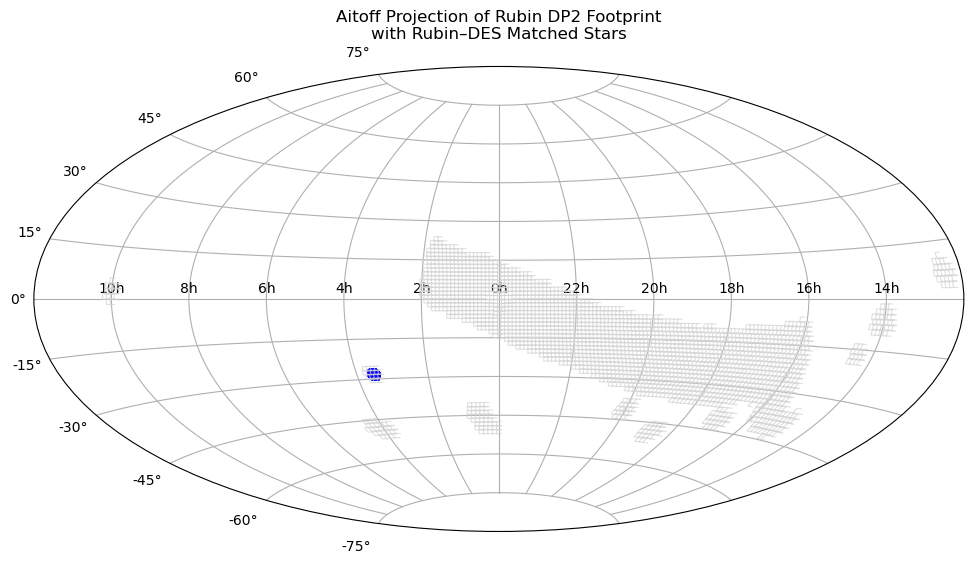

In [20]:
# Plot Aitoff sky plot of new match file...

#if not useMatchFile:
if True:
    
    # ------------------------------------------------------------
    # Extract RA/Dec from your final matches table
    # ------------------------------------------------------------
    ra = matches["coord_ra"].values
    dec = matches["coord_dec"].values

    # Convert RA to [-180, +180] degrees
    ra_wrapped = np.remainder(ra + 180.0, 360.0) - 180.0

    # Convert to radians
    ra_rad = np.deg2rad(-ra_wrapped)
    dec_rad = np.deg2rad(dec)

    # ------------------------------------------------------------
    # Self-contained: find ONLY the tracts that contain DP2 data
    # ------------------------------------------------------------
    _but = Butler(repo, collections=collection)

    # Query all object-table datasets in the DP2 collection
    refs = list(_but.registry.queryDatasets(
        "object",
        collections=[collection],
        findFirst=True
    ))

    # Extract unique tract IDs
    dp2_tracts = sorted({ref.dataId["tract"] for ref in refs})

    # Load skymap
    _skymap = _but.get("skyMap", skymap="lsst_cells_v2")

    # Convert tract polygons to RA/Dec
    def _tract_vertices_deg(tract):
        poly = tract.getOuterSkyPolygon()
        verts = poly.getVertices()
        ra_list, dec_list = [], []
        for v in verts:
            sp = geom.SpherePoint(v)
            ra_list.append(sp.getRa().asDegrees())
            dec_list.append(sp.getDec().asDegrees())
        return list(zip(ra_list, dec_list))

    # Build list of polygons for DP2 tracts only
    _dp2_vertices = [_tract_vertices_deg(_skymap[tid]) for tid in dp2_tracts]

    # ------------------------------------------------------------
    # Create Aitoff projection
    # ------------------------------------------------------------
    plt.figure(figsize=(12, 7))
    ax = plt.subplot(111, projection="aitoff")

    # ------------------------------------------------------------
    # 1. Plot ONLY Rubin DP2 tracts (not full skymap)
    # ------------------------------------------------------------
    for vertices in _dp2_vertices:
        ra_poly = np.array([v[0] for v in vertices])
        dec_poly = np.array([v[1] for v in vertices])

        # Wrap RA to [-180, +180]
        ra_poly_wrapped = np.remainder(ra_poly + 180.0, 360.0) - 180.0

        # Convert to radians
        ra_poly_rad = np.deg2rad(-ra_poly_wrapped)
        dec_poly_rad = np.deg2rad(dec_poly)

        ax.plot(ra_poly_rad, dec_poly_rad,
                color="lightgray", linewidth=0.8, alpha=0.7)

    # ------------------------------------------------------------
    # 2. Plot matched stars on top
    # ------------------------------------------------------------
    ax.scatter(ra_rad, dec_rad, s=1, alpha=0.5, color="blue")
    #ax.set_xticklabels(['14h','16h','18h','20h','22h','0h','2h','4h','6h','8h','10h'])
    ax.set_xticklabels(['10h','8h','6h','4h','2h','0h','22h','20h','18h','16h','14h'])

    ax.grid(True)
    plt.title("Aitoff Projection of Rubin DP2 Footprint\nwith Rubin–DES Matched Stars", pad=20)

    # Save to PNG file
    plt.savefig(aitoffPlotFileName, dpi=200, bbox_inches="tight")

    # Plot to screen
    plt.show()


##  7. Add ABmag Columns to Matched Catalog Data Frame

In [21]:
# Copy matches to df...
df = matches.copy()

In [22]:
# Define common parameters
flux_bands = ['u', 'g', 'r', 'i', 'z', 'y']
offset = 31.4 # For magnitude calculation
sentinel_value = -9999.0

# Loop through each band to calculate both magnitude and magnitude error
for band in flux_bands:
    
    flux_col = f'{band}_psfFlux'
    flux_err_col = f'{band}_psfFluxErr'
    mag_col = f'{band}_psfMag'
    mag_err_col = f'{band}_psfMagErr'

    # Condition for valid flux (must be positive for log10 and division)
    valid_flux_condition = df[flux_col] > 0

    # Calculate magnitude
    df[mag_col] = np.where(valid_flux_condition,
                           -2.5 * np.log10(df[flux_col]) + offset,
                           sentinel_value)

    # Calculate magnitude error
    df[mag_err_col] = np.where(valid_flux_condition,
                               1.086 * df[flux_err_col] / df[flux_col],
                               sentinel_value)



/opt/lsst/software/stack/conda/envs/lsst-scipipe-10.1.0-exact/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/lsst/software/stack/conda/envs/lsst-scipipe-10.1.0-exact/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/lsst/software/stack/conda/envs/lsst-scipipe-10.1.0-exact/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [23]:
df

,tractId,coord_ra,coord_dec,tract,patch,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_cModelFlux,...,g_psfMag,g_psfMagErr,r_psfMag,r_psfMagErr,i_psfMag,i_psfMagErr,z_psfMag,z_psfMagErr,y_psfMag,y_psfMagErr
0,4636,51.996614,-29.876283,4636,80,NaN,NaN,NaN,NaN,NaN,...,20.507681,0.005131,19.182608,0.003177,17.557373,0.000683,16.855258,0.001211,16.461624,0.002491
1,4636,51.986158,-29.924198,4636,80,NaN,NaN,NaN,NaN,NaN,...,16.990315,0.001108,16.622247,0.000973,16.484389,0.000558,16.470181,0.001027,16.469976,0.002567
2,4636,51.984583,-29.877539,4636,80,NaN,NaN,NaN,NaN,NaN,...,19.957020,0.004621,18.572140,0.002347,17.410313,0.000766,16.937185,0.001264,16.691312,0.002956
3,4636,51.980097,-29.866664,4636,80,NaN,NaN,NaN,NaN,NaN,...,19.937142,0.003639,18.665183,0.002393,17.607191,0.000673,17.186623,0.001181,16.972809,0.003596
4,4636,52.027173,-29.843797,4636,80,NaN,NaN,NaN,NaN,NaN,...,20.193050,0.004192,18.871564,0.002043,18.151711,0.000914,17.837330,0.002175,17.685810,0.006081
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8535,5281,53.585532,-26.276732,5281,38,NaN,NaN,7806.068,inf,NaN,...,19.159838,0.003115,17.716344,0.001385,16.144446,0.000295,15.544431,0.000551,15.169387,0.001071
8536,5281,53.586680,-26.271328,5281,38,NaN,NaN,12031.031,inf,NaN,...,16.738318,0.000987,16.135495,0.000697,15.936574,0.000281,15.871468,0.000485,-9999.000000,-9999.000000
8537,5281,53.510990,-26.256043,5281,38,NaN,NaN,-8307.214,inf,NaN,...,19.138120,0.003096,17.862112,0.001923,17.053028,0.000420,16.701354,0.001014,16.552318,0.001840
8538,5281,53.443070,-26.274773,5281,39,NaN,NaN,NaN,NaN,NaN,...,16.353938,0.000841,15.830551,0.000767,15.664957,0.000232,15.672941,0.000491,15.588546,0.001013


In [24]:
df.columns

Index(['tractId', 'coord_ra', 'coord_dec', 'tract', 'patch', 'u_psfFlux',
       'u_psfFluxErr', 'u_ap12Flux', 'u_ap12FluxErr', 'u_cModelFlux',
       'u_cModelFluxErr', 'u_extendedness', 'u_psfFlux_flag', 'g_psfFlux',
       'g_psfFluxErr', 'g_ap12Flux', 'g_ap12FluxErr', 'g_cModelFlux',
       'g_cModelFluxErr', 'g_extendedness', 'g_psfFlux_flag', 'r_psfFlux',
       'r_psfFluxErr', 'r_ap12Flux', 'r_ap12FluxErr', 'r_cModelFlux',
       'r_cModelFluxErr', 'r_extendedness', 'r_psfFlux_flag', 'i_psfFlux',
       'i_psfFluxErr', 'i_ap12Flux', 'i_ap12FluxErr', 'i_cModelFlux',
       'i_cModelFluxErr', 'i_extendedness', 'i_psfFlux_flag', 'z_psfFlux',
       'z_psfFluxErr', 'z_ap12Flux', 'z_ap12FluxErr', 'z_cModelFlux',
       'z_cModelFluxErr', 'z_extendedness', 'z_psfFlux_flag', 'y_psfFlux',
       'y_psfFluxErr', 'y_ap12Flux', 'y_ap12FluxErr', 'y_cModelFlux',
       'y_cModelFluxErr', 'y_extendedness', 'y_psfFlux_flag', 'match_idx',
       'separation_arcsec', 'match_source_id', 'match_ra

In [25]:
# Rename columns...
df.rename(columns={'coord_ra':'RA_LSST',
                   'coord_dec':'DEC_LSST',
                   'g_psfMag':'g_LSST',
                   'r_psfMag':'r_LSST',
                   'i_psfMag':'i_LSST',
                   'z_psfMag':'z_LSST',
                   'y_psfMag':'y_LSST',
                   'g_psfMagErr':'g_err_LSST',
                   'r_psfMagErr':'r_err_LSST',
                   'i_psfMagErr':'i_err_LSST',
                   'z_psfMagErr':'z_err_LSST',
                   'y_psfMagErr':'y_err_LSST',
                   'match_phot_g_mean_mag':'G_gaia',
                   'match_phot_g_mean_mag_error':'G_err_gaia', 
                   'match_phot_bp_mean_mag':'BP_gaia',
                   'match_phot_bp_mean_mag_error':'BP_err_gaia',
                   'match_phot_rp_mean_mag':'RP_gaia',
                   'match_phot_rp_mean_mag_error':'RP_err_gaia', 
                   'match_bp_rp':'BP_RP_gaia'
                  },inplace=True)

df.head(5)

,tractId,RA_LSST,DEC_LSST,tract,patch,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_cModelFlux,...,g_LSST,g_err_LSST,r_LSST,r_err_LSST,i_LSST,i_err_LSST,z_LSST,z_err_LSST,y_LSST,y_err_LSST
0,4636,51.996614,-29.876283,4636,80,NaN,NaN,NaN,NaN,NaN,...,20.507681,0.005131,19.182608,0.003177,17.557373,0.000683,16.855258,0.001211,16.461624,0.002491
1,4636,51.986158,-29.924198,4636,80,NaN,NaN,NaN,NaN,NaN,...,16.990315,0.001108,16.622247,0.000973,16.484389,0.000558,16.470181,0.001027,16.469976,0.002567
2,4636,51.984583,-29.877539,4636,80,NaN,NaN,NaN,NaN,NaN,...,19.957020,0.004621,18.572140,0.002347,17.410313,0.000766,16.937185,0.001264,16.691312,0.002956
3,4636,51.980097,-29.866664,4636,80,NaN,NaN,NaN,NaN,NaN,...,19.937142,0.003639,18.665183,0.002393,17.607191,0.000673,17.186623,0.001181,16.972809,0.003596
4,4636,52.027173,-29.843797,4636,80,NaN,NaN,NaN,NaN,NaN,...,20.193050,0.004192,18.871564,0.002043,18.151711,0.000914,17.837330,0.002175,17.685810,0.006081


In [26]:
df.columns

Index(['tractId', 'RA_LSST', 'DEC_LSST', 'tract', 'patch', 'u_psfFlux',
       'u_psfFluxErr', 'u_ap12Flux', 'u_ap12FluxErr', 'u_cModelFlux',
       'u_cModelFluxErr', 'u_extendedness', 'u_psfFlux_flag', 'g_psfFlux',
       'g_psfFluxErr', 'g_ap12Flux', 'g_ap12FluxErr', 'g_cModelFlux',
       'g_cModelFluxErr', 'g_extendedness', 'g_psfFlux_flag', 'r_psfFlux',
       'r_psfFluxErr', 'r_ap12Flux', 'r_ap12FluxErr', 'r_cModelFlux',
       'r_cModelFluxErr', 'r_extendedness', 'r_psfFlux_flag', 'i_psfFlux',
       'i_psfFluxErr', 'i_ap12Flux', 'i_ap12FluxErr', 'i_cModelFlux',
       'i_cModelFluxErr', 'i_extendedness', 'i_psfFlux_flag', 'z_psfFlux',
       'z_psfFluxErr', 'z_ap12Flux', 'z_ap12FluxErr', 'z_cModelFlux',
       'z_cModelFluxErr', 'z_extendedness', 'z_psfFlux_flag', 'y_psfFlux',
       'y_psfFluxErr', 'y_ap12Flux', 'y_ap12FluxErr', 'y_cModelFlux',
       'y_cModelFluxErr', 'y_extendedness', 'y_psfFlux_flag', 'match_idx',
       'separation_arcsec', 'match_source_id', 'match_ra',

## 8. Add Color Columns to Matched Catalog Data Frame

In [27]:
# Add color columns...
df.loc[:,'gr_LSST'] = df.loc[:,'g_LSST'] - df.loc[:,'r_LSST']
df.loc[:,'ri_LSST'] = df.loc[:,'r_LSST'] - df.loc[:,'i_LSST']
df.loc[:,'iz_LSST'] = df.loc[:,'i_LSST'] - df.loc[:,'z_LSST']
df.loc[:,'zy_LSST'] = df.loc[:,'z_LSST'] - df.loc[:,'y_LSST']
df.loc[:,'gi_LSST'] = df.loc[:,'g_LSST'] - df.loc[:,'i_LSST']

In [28]:
# Insert dmag column...
df.loc[:,'dmag'] = -9999.

## 9. Create Initial Mask

In [29]:
mask1 = (df["g_LSST"] > 16.5)
mask2 = (df["r_LSST"] > 16.5)
mask3 = (df["i_LSST"] > 16.5)
mask4 = (df["z_LSST"] > 16.5)
mask5 = (df["y_LSST"] > 16.5)
mask6 = df["g_err_LSST"] <= 0.05
mask7 = df["r_err_LSST"] <= 0.05
mask8 = df["i_err_LSST"] <= 0.05
mask9 = df["z_err_LSST"] <= 0.05
mask10 = df["y_err_LSST"] <= 0.10
mask_LSST = mask1 & mask2 & mask3 & mask4 & mask5 & mask6 & mask7 & mask8 & mask9 & mask10

mask1 = (df["G_gaia"] > 0.) & (df["G_gaia"] < 30.)
mask2 = (df["BP_gaia"] > 0.) & (df["BP_gaia"] < 30.)
mask3 = (df["RP_gaia"] > 0.) & (df["RP_gaia"] < 30.)
mask4 = (df["G_err_gaia"] > 0.00) & (df["G_err_gaia"] <= 0.05)
mask5 = (df["BP_err_gaia"] > 0.00) & (df["BP_err_gaia"] <= 0.05)
mask6 = (df["RP_err_gaia"] > 0.00) & (df["RP_err_gaia"] <= 0.05)
mask_Gaia = mask1 & mask2 & mask3  & mask4 & mask5 & mask6


mask = mask_LSST & mask_Gaia


In [30]:
df

,tractId,RA_LSST,DEC_LSST,tract,patch,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_cModelFlux,...,z_LSST,z_err_LSST,y_LSST,y_err_LSST,gr_LSST,ri_LSST,iz_LSST,zy_LSST,gi_LSST,dmag
0,4636,51.996614,-29.876283,4636,80,NaN,NaN,NaN,NaN,NaN,...,16.855258,0.001211,16.461624,0.002491,1.325072,1.625235,0.702115,0.393634,2.950308,-9999.0
1,4636,51.986158,-29.924198,4636,80,NaN,NaN,NaN,NaN,NaN,...,16.470181,0.001027,16.469976,0.002567,0.368067,0.137858,0.014208,0.000205,0.505925,-9999.0
2,4636,51.984583,-29.877539,4636,80,NaN,NaN,NaN,NaN,NaN,...,16.937185,0.001264,16.691312,0.002956,1.384880,1.161827,0.473128,0.245872,2.546707,-9999.0
3,4636,51.980097,-29.866664,4636,80,NaN,NaN,NaN,NaN,NaN,...,17.186623,0.001181,16.972809,0.003596,1.271959,1.057992,0.420568,0.213814,2.329952,-9999.0
4,4636,52.027173,-29.843797,4636,80,NaN,NaN,NaN,NaN,NaN,...,17.837330,0.002175,17.685810,0.006081,1.321486,0.719853,0.314381,0.151520,2.041339,-9999.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8535,5281,53.585532,-26.276732,5281,38,NaN,NaN,7806.068,inf,NaN,...,15.544431,0.000551,15.169387,0.001071,1.443494,1.571898,0.600015,0.375044,3.015392,-9999.0
8536,5281,53.586680,-26.271328,5281,38,NaN,NaN,12031.031,inf,NaN,...,15.871468,0.000485,-9999.000000,-9999.000000,0.602823,0.198921,0.065106,10014.871468,0.801744,-9999.0
8537,5281,53.510990,-26.256043,5281,38,NaN,NaN,-8307.214,inf,NaN,...,16.701354,0.001014,16.552318,0.001840,1.276008,0.809084,0.351674,0.149036,2.085092,-9999.0
8538,5281,53.443070,-26.274773,5281,39,NaN,NaN,NaN,NaN,NaN,...,15.672941,0.000491,15.588546,0.001013,0.523388,0.165594,-0.007984,0.084395,0.688982,-9999.0


## 10. Make Backup Copies of Initial Mask and Original Data Frame

In [31]:
# Make a backup copy of original df...
df_orig = df.copy()

# Make a backup copy of original mask...
mask_orig = mask.copy()

## 11. Run Fit in Each Filter Band

/tmp/ipykernel_11932/2942279713.py:84: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grp = df.groupby(['bin_label'])





# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 
G_gaia
# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 


count    3403.000000
mean        1.767065
std         0.679663
min        -0.729811
1%          0.372054
50%         1.949358
99%         2.808268
max         3.571606
Name: gi_LSST, dtype: float64
0.3 2.9

[0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7 1.8 1.9 2.
 2.1 2.2 2.3 2.4 2.5 2.6 2.7 2.8 2.9]
[0.35 0.45 0.55 0.65 0.75 0.85 0.95 1.05 1.15 1.25 1.35 1.45 1.55 1.65
 1.75 1.85 1.95 2.05 2.15 2.25 2.35 2.45 2.55 2.65 2.75 2.85]

     gi_LSST bin_interval bin_label
2   2.546707   (2.5, 2.6]      2.55
3   2.329952   (2.3, 2.4]      2.35
4   2.041339   (2.0, 2.1]      2.05
11  2.488042   (2.4, 2.5]      2.45
12  1.813173   (1.8, 1.9]      1.85


          bin_interval  bin_num  bin_mean  bin_stddev  bin_stderr  bin_median  \
bin_label                                                                       
0.3

/tmp/ipykernel_11932/1197615696.py:131: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()





# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 
BP_gaia
# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 


count    3403.000000
mean        1.767065
std         0.679663
min        -0.729811
1%          0.372054
50%         1.949358
99%         2.808268
max         3.571606
Name: gi_LSST, dtype: float64
0.3 2.9

[0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7 1.8 1.9 2.
 2.1 2.2 2.3 2.4 2.5 2.6 2.7 2.8 2.9]
[0.35 0.45 0.55 0.65 0.75 0.85 0.95 1.05 1.15 1.25 1.35 1.45 1.55 1.65
 1.75 1.85 1.95 2.05 2.15 2.25 2.35 2.45 2.55 2.65 2.75 2.85]

     gi_LSST bin_interval bin_label
2   2.546707   (2.5, 2.6]      2.55
3   2.329952   (2.3, 2.4]      2.35
4   2.041339   (2.0, 2.1]      2.05
11  2.488042   (2.4, 2.5]      2.45
12  1.813173   (1.8, 1.9]      1.85


          bin_interval  bin_num  bin_mean  bin_stddev  bin_stderr  bin_median  \
bin_label                                                                       
0.

/tmp/ipykernel_11932/2942279713.py:84: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grp = df.groupby(['bin_label'])
/tmp/ipykernel_11932/1197615696.py:131: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()





# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 
RP_gaia
# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 


count    3403.000000
mean        1.767065
std         0.679663
min        -0.729811
1%          0.372054
50%         1.949358
99%         2.808268
max         3.571606
Name: gi_LSST, dtype: float64
0.3 2.9

[0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7 1.8 1.9 2.
 2.1 2.2 2.3 2.4 2.5 2.6 2.7 2.8 2.9]
[0.35 0.45 0.55 0.65 0.75 0.85 0.95 1.05 1.15 1.25 1.35 1.45 1.55 1.65
 1.75 1.85 1.95 2.05 2.15 2.25 2.35 2.45 2.55 2.65 2.75 2.85]

     gi_LSST bin_interval bin_label
2   2.546707   (2.5, 2.6]      2.55
3   2.329952   (2.3, 2.4]      2.35
4   2.041339   (2.0, 2.1]      2.05
11  2.488042   (2.4, 2.5]      2.45
12  1.813173   (1.8, 1.9]      1.85


          bin_interval  bin_num  bin_mean  bin_stddev  bin_stderr  bin_median  \
bin_label                                                                       
0.

/tmp/ipykernel_11932/2942279713.py:84: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grp = df.groupby(['bin_label'])
/tmp/ipykernel_11932/1197615696.py:131: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


| Conversion               |   RMS | Applicable Color Range     | QA Plot                                                                          | Lookup Table                                                             |
|:-------------------------|------:|:---------------------------|:---------------------------------------------------------------------------------|:-------------------------------------------------------------------------|
| $r_{LSST} \to G_{gaia}$  | 0.02  | $0.3 < (g-i)_{LSST} < 2.9$ | [link](_static/plots/qaPlot_transInterp.LSST_DR2_to_GaiaDR3.G_gaia_gi_LSST.png)  | [link](_static/data/transInterp.LSST_DR2_to_GaiaDR3.G_gaia_gi_LSST.csv)  |
| $g_{LSST} \to BP_{gaia}$ | 0.025 | $0.3 < (g-i)_{LSST} < 2.9$ | [link](_static/plots/qaPlot_transInterp.LSST_DR2_to_GaiaDR3.BP_gaia_gi_LSST.png) | [link](_static/data/transInterp.LSST_DR2_to_GaiaDR3.BP_gaia_gi_LSST.csv) |
| $r_{LSST} \to RP_{gaia}$ | 0.028 | $0.3 < (g-i)_{LSST} < 2.9$ | [link](_static/plots/qaPlot_transInter

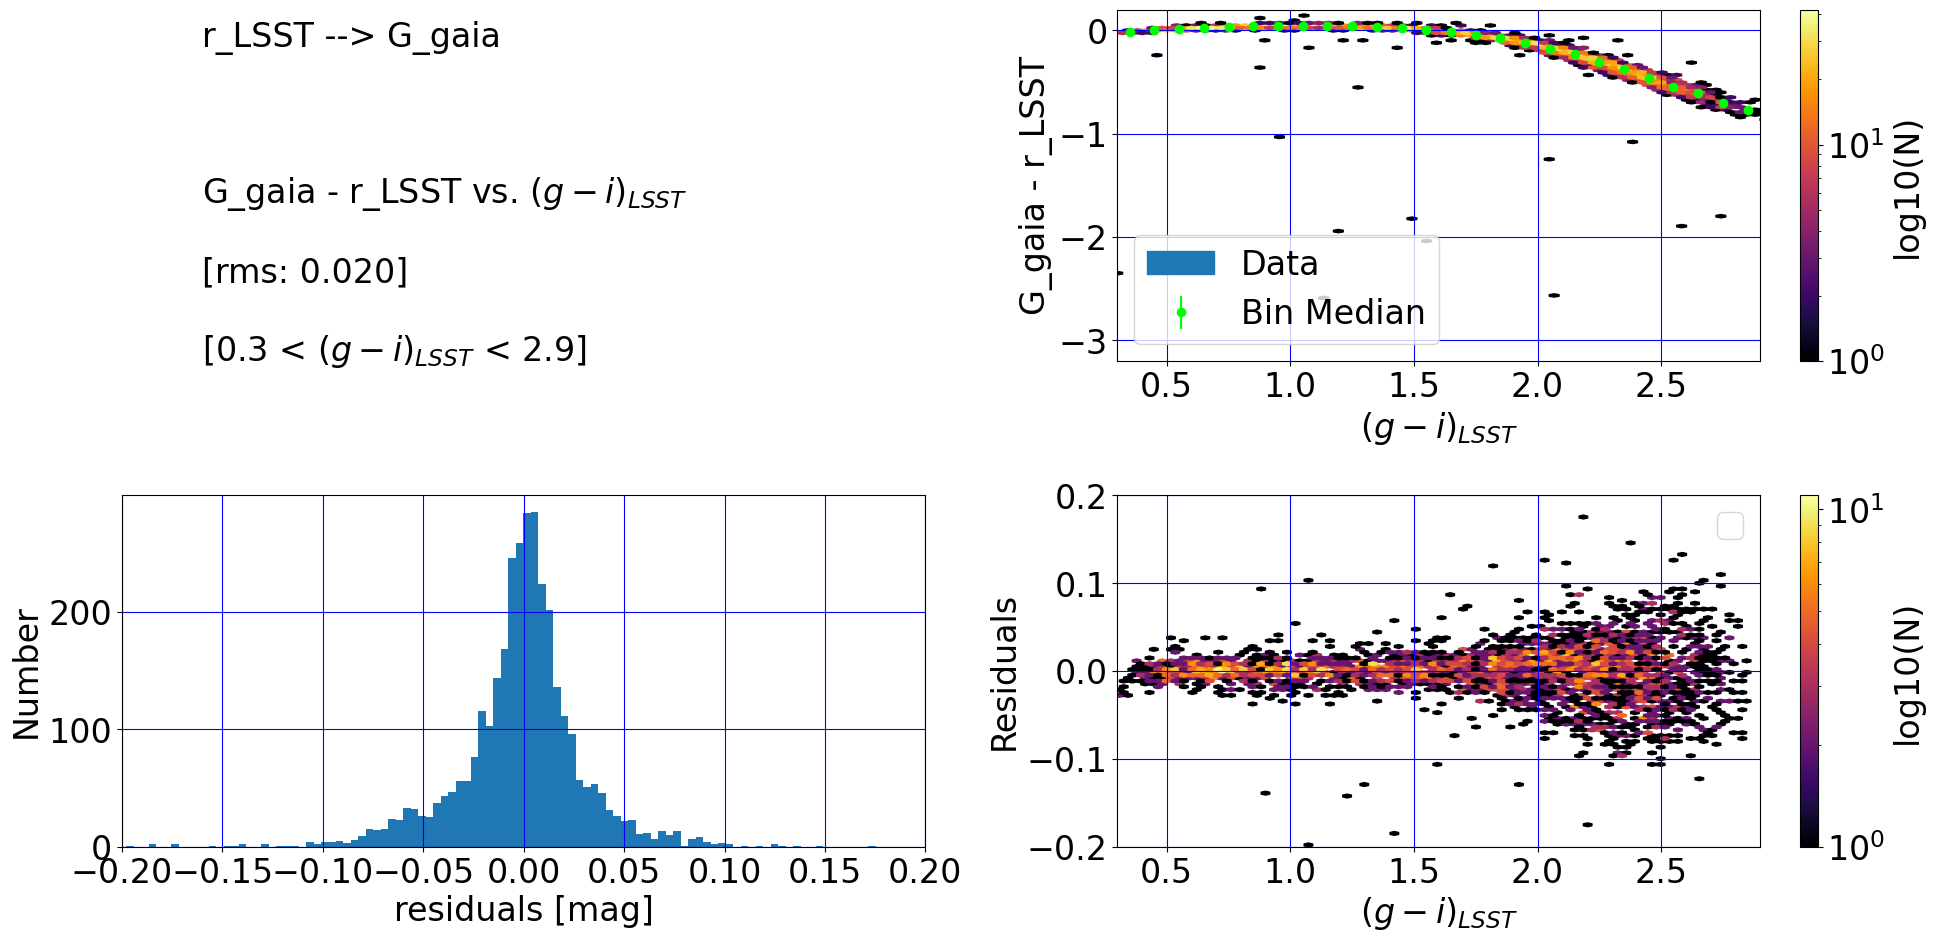

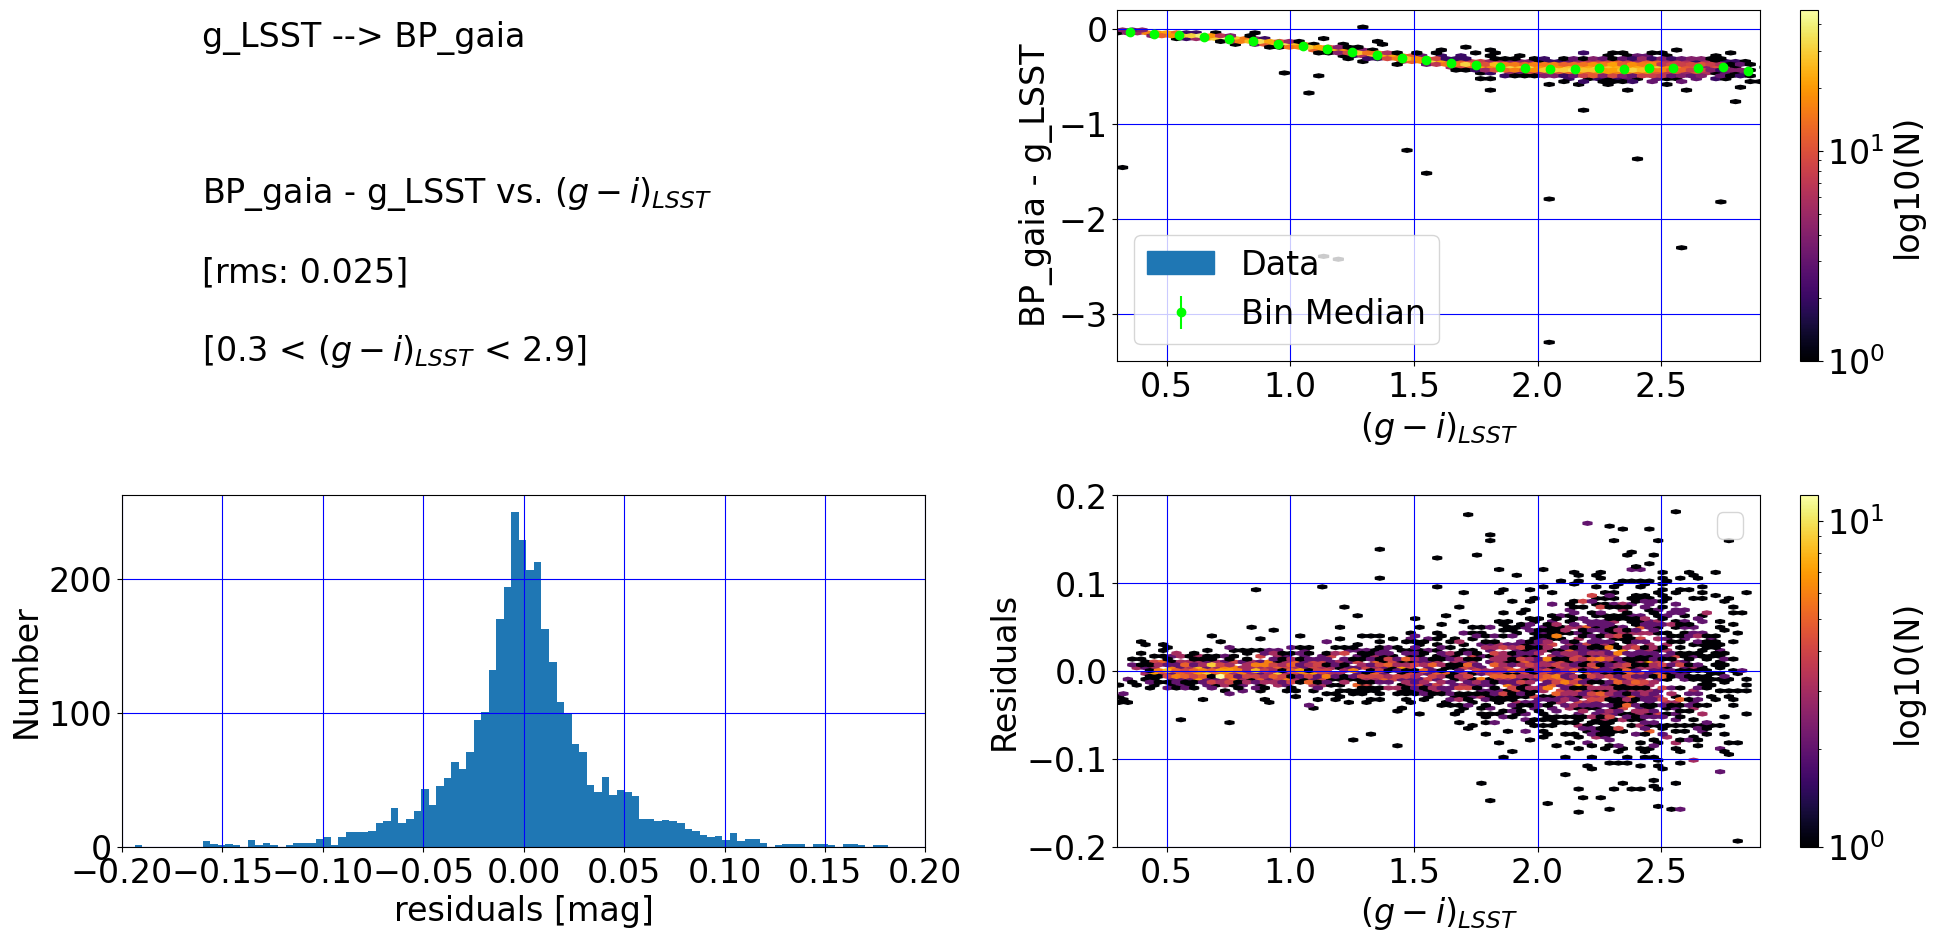

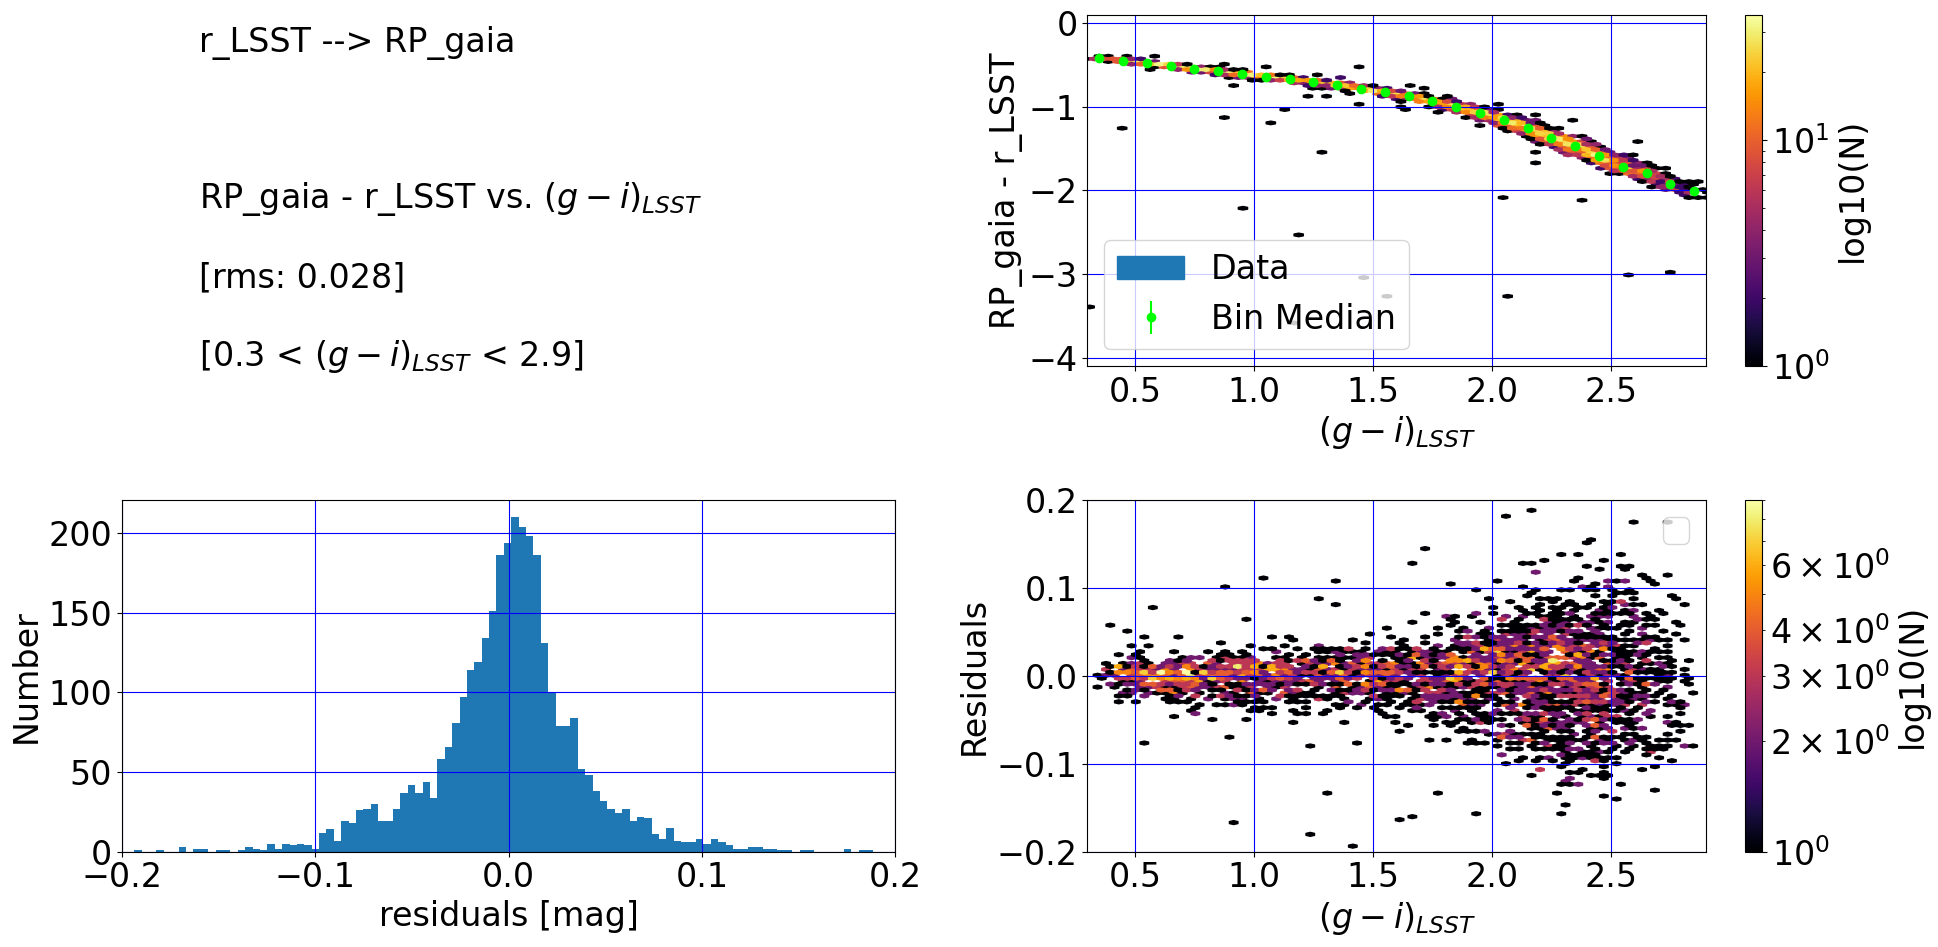

In [32]:
# --- Accumulator for ALL bands ---
qa_rows_all = []

# --- Main loop ---
for band in bandList:
    
    print("")
    print("")
    print("") 
    print("# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # ")
    print(band)
    print("# # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # ")
    print("")
    
    magName = band
    magName_match = matchBand_dict[band]
    color_name_1 = color_name_1_dict[band]
    colorLabel_1 = colorLabel_1_dict[band]

    
    # Grab the original version of df from the backup copy...
    df = df_orig.copy()

    # Grab the original version of mask from the backup copy...
    mask = mask_orig.copy()

    # Update dmag column...
    df.loc[:,'dmag'] = df.loc[:,magName] - df.loc[:,magName_match]

    # Update mask...
    mask1 = abs(df['dmag']) <= 10.
    mask2 = ( ( df[color_name_1] > -3. ) & ( df[color_name_1] < 6.0 ) )
    mask = mask & mask1 & mask2

    # make a copy of original df, overwriting the old one...
    df = df[mask].copy()

    # Identify dmag and color1 series...
    dmag =  df.loc[:,'dmag']
    color1 = df.loc[:,color_name_1]


    # Calculate the color range to bin and the number of bins, 
    #  based on the 0.01%-99.99% color range...
    #color1_desc = df[color_name_1].describe(percentiles=[0.0001, 0.9999])
    #color1_min = math.floor(10*color1_desc['0.01%'])/10.
    #color1_max = math.ceil(10*color1_desc['99.99%'])/10.
    color1_desc = df[color_name_1].describe(percentiles=[0.01, 0.99])
    color1_min = math.floor(10*color1_desc['1%'])/10.
    color1_max = math.ceil(10*color1_desc['99%'])/10.
    if verbose>1:
        print("")
        print(color1_desc)
        print(color1_min, color1_max)
        print("")
    binsize = color_binsize
    ranges = np.arange(color1_min,color1_max+binsize,binsize)
    # Label the bins by their mid-point...
    labels = np.arange(color1_min,color1_max,binsize) + 0.5*binsize
    
    #nbins = int((color1_max-color1_min)/binsize)+1
    #ranges = np.linspace(color1_min, color1_max, nbins+1)
    ## Label the bins by their mid-point...
    #labels = np.linspace(color1_min, color1_max-binsize, nbins) + 0.5*binsize

    #nbins = math.floor((color1_max-color1_min)/binsize) + 1
    #ranges = np.linspace(color1_min, color1_max, nbins)
    ## Label the bins by their mid-point...
    #labels = np.linspace(color1_min, color1_max-binsize, nbins-1) + 0.5*binsize
    
    if verbose:
        print(ranges)
        print(labels)
    
    # Bin the data, adding "bin_interval" and "bin_label' to the df dataframe...
    df['bin_interval'] = pd.cut(df[color_name_1], bins=ranges, precision=0)
    df['bin_label'] = pd.cut(df[color_name_1], bins=ranges, labels=labels)
    if verbose>1:
        print("")
        print(df[[color_name_1,'bin_interval','bin_label']].head())
        print("")

    # Perform pandas grouping/aggregating functions on sigma-clipped Data Frame...
    df_grp = df.groupby(['bin_label'])
    bin_interval = df_grp['bin_interval'].first()
    dmag_num = df_grp['dmag'].count()
    dmag_mean = df_grp['dmag'].mean()
    dmag_sd = df_grp['dmag'].std()
    dmag_err = dmag_sd/np.sqrt(dmag_num-1)
    dmag_median = df_grp['dmag'].median()
    dmag_rsd = df_grp['dmag'].apply(robustStdDev)
    dmag_unc = np.sqrt(np.pi/2)*dmag_rsd/np.sqrt(dmag_num)
    #dmag_rsd = dmag_sd
    #dmag_unc = dmag_err

    # Rename some of the pandas series...
    dmag_num.name    = 'bin_num'
    dmag_mean.name   = 'bin_mean'
    dmag_sd.name     = 'bin_stddev'
    dmag_err.name    = 'bin_stderr'
    dmag_median.name = 'bin_median'
    dmag_rsd.name    = 'bin_rstddev'
    dmag_unc.name    = 'bin_unc'
    
    # Create new data frame containing all the relevant aggregate quantities...
    df1 = pd.concat( [bin_interval, dmag_num, \
                      dmag_mean, dmag_sd, dmag_err, \
                      dmag_median, dmag_rsd, dmag_unc, ], \
                    join='outer', axis=1 )
    
    if verbose>1:
        print("")
        print(df1)
        print("")
    
    
    # Create results output file...
    resultsFile = """%s.%s_%s.csv""" % (resultsFileBaseName, band, color_name_1)
    df1.to_csv(resultsFile)
    if verbose>1:
        print("""Writing binned values to %s""" % (resultsFile))

    
    # Create name for QA plot output file...
    outputFileName = """qaPlot_%s.%s_%s.png""" % (resultsFileBaseName, band, color_name_1)

    # Create title and labels for use in QA plots...
    title = """%s --> %s""" % (magName_match, magName)
    dmagLabel = """%s - %s""" % (magName, magName_match)


    # Create QA plots...
    status = interp1ColorQAPlots1(df, df1, color_name_1, color1_min, color1_max, 
                                     title, dmagLabel, outputFileName, verbose)

    # Calculate the 'robust' RMS of the residuals....
    #rms_val = df1['bin_rstddev'].median()  # or mean, or df1['bin_unc'].median()
    rms_val = robustStdDev(df['res'].values)
    rms_val = round(rms_val, 3)

    conversion_str = make_conversion_str(magName_match, magName)
    range_str = make_range_str_interp(color1_min, color1_max, colorLabel_1)

    qa_rows_all.append({
        "Conversion": conversion_str,
        "RMS": rms_val,
        "Applicable Color Range": range_str,
        "QA Plot": f"[link](_static/plots/{outputFileName})",
        "Lookup Table": f"[link](_static/data/{resultsFile})"
    })


# --- After ALL bands processed: display one big table ---
if qa_rows_all:
    qa_df_all = pd.DataFrame(qa_rows_all)
    md_table_str = qa_df_all.to_markdown(index=False)
    md_table_str = md_table_str.replace(r'\_', '_')
    print(md_table_str)

    if write_md_file:
        with open(md_filename, "w") as f:
            f.write(md_table_str)
        print(f"\nMarkdown table written to: {md_filename}")
  